# Notebook 01 - EDA & Data Cleaning (Module 1)
Project : readmission prediction on the Diabetes 130-US hospitals dataset (Kaggle `brandao/diabetes`).

Ce notebook charge les données brutes, les nettoie et sauvegarde un fichier propre dans `data/processed/`. On garde `patient_nbr` dans le fichier car le notebook 02 en a besoin pour le split par patient.

## 1. Imports and paths

In [60]:
import os #pour gérer les dossiers et les chemins
import numpy as np #pour les calculs numériques
import pandas as pd #pour manipuler les tableaux
import matplotlib.pyplot as plt #pour faire les graphiques
import seaborn as sns #pour des graphiques plus jolis
sns.set_theme(style="whitegrid") #style simple pour tous les graphiques
pd.set_option("display.max_columns", 60) #affiche toutes les colonnes des tableaux
PROCESSED_DIR = os.path.join("..", "data", "processed") #dossier où on sauvegarde le fichier nettoyé

**Ce que fait ce code :** on importe les librairies et on définit des chemins relatifs. Comme ça le notebook tourne sur toutes les machines sans rien changer.

**À faire avant :** télécharger `diabetic_data.csv` sur Kaggle et le mettre dans `data/raw/`.

## 2. Loading the data

In [64]:
RAW_PATH = "https://raw.githubusercontent.com/AmandineBaranger/Group_06_DS_Project/main/data/raw/diabetic_data.csv"
df = pd.read_csv(RAW_PATH) #charge le fichier csv dans un tableau pandas
print("Shape :", df.shape) #affiche le nombre de lignes et de colonnes
df.head() #montre les 5 premières lignes

Shape : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [65]:
print(df.dtypes.value_counts()) #compte le nombre de colonnes par type
df.describe().T #résumé statistique des colonnes numériques

str      37
int64    13
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


**Ce que fait ce code :** `shape` donne la taille du tableau. `head` permet de voir à quoi ressemblent les lignes. `dtypes` compte les types de colonnes et `describe` donne la moyenne, le min et le max des variables numériques.

**Interprétation :** le dataset fait environ 100 000 lignes pour une cinquantaine de colonnes (à vérifier avec ta sortie). La plupart des colonnes sont de type `object` (catégories) et le reste est numérique. Les colonnes finissant par `_id` sont des codes et pas de vrais nombres. On les traitera comme des catégories dans le notebook 02.

## 3. Missing values (`?` to NaN)

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


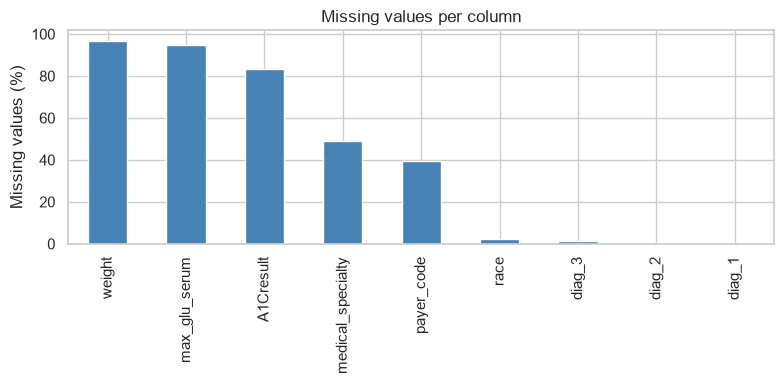

In [70]:
df = df.replace("?", np.nan) #remplace les "?" par de vrais NaN pour que pandas les reconnaisse
missing = df.isna().mean().mul(100).sort_values(ascending=False) #pourcentage de manquants par colonne
missing = missing[missing > 0] #garde seulement les colonnes qui ont des manquants
print(missing.round(2)) #affiche les pourcentages arrondis
plt.figure(figsize=(8, 4)) #taille du graphique
missing.plot(kind="bar", color="steelblue") #diagramme en barres des manquants
plt.ylabel("Missing values (%)") #nom de l'axe y
plt.title("Missing values per column") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche le graphique

**Ce que fait ce code :** dans ce dataset les manquants sont écrits avec un `?`. On les transforme en `NaN` puis on calcule le pourcentage de manquants par colonne.

**Interprétation :** en général `weight` est manquante à environ 97 %. Elle est donc inutilisable. `medical_specialty` (environ 49 %) et `payer_code` (environ 40 %) sont aussi très incomplètes. `race` a environ 2 % de manquants et les colonnes `diag_1/2/3` en ont très peu. On adapte les décisions avec tes chiffres réels.

## 4. Handling missing values

In [74]:
df = df.drop(columns=["weight", "payer_code"]) #supprime weight (trop de manquants) et payer_code (peu utile médicalement)
df["medical_specialty"] = df["medical_specialty"].fillna("Missing") #garde la colonne avec une catégorie "Missing"
df["race"] = df["race"].fillna("Unknown") #remplace les race manquantes par "Unknown"
print(df.isna().sum()[df.isna().sum() > 0]) #vérifie ce qui reste comme manquants (les diag)

diag_1              21
diag_2             358
diag_3            1423
max_glu_serum    96420
A1Cresult        84748
dtype: int64


**Ce que fait ce code :** on supprime les colonnes presque vides et on remplace les manquants de `medical_specialty` et `race` par une catégorie constante. Remplir avec une constante n'apprend rien sur les données donc il n'y a pas de fuite.

**Interprétation :** il ne reste que quelques manquants dans `diag_1/2/3`. On les garde en NaN. Ils seront gérés dans le notebook 02 avec le regroupement des codes ICD-9. Si on voulait imputer avec une moyenne ou une médiane il faudrait le faire dans un Pipeline après le split.

## 5. Duplicates and invalid rows

In [78]:
print("Duplicated rows :", df.duplicated().sum()) #compte les lignes entièrement identiques
print("Duplicated encounter_id :", df["encounter_id"].duplicated().sum()) #compte les hospitalisations en double
df = df.drop_duplicates() #supprime les lignes en double
print(df["gender"].value_counts()) #regarde les valeurs de gender
df = df[df["gender"] != "Unknown/Invalid"] #supprime les quelques lignes avec un genre invalide
print("Shape after cleaning :", df.shape) #affiche la nouvelle taille

Duplicated rows : 0
Duplicated encounter_id : 0
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
Shape after cleaning : (101763, 48)


**Ce que fait ce code :** on cherche les doublons (lignes identiques ou même `encounter_id`) puis on retire les lignes avec un genre invalide.

**Interprétation :** normalement il n'y a pas de doublon dans ce dataset et seulement 3 lignes avec `Unknown/Invalid`. Le nettoyage est donc léger. Cette vérification reste utile pour prouver qu'on n'a pas supposé que les données étaient propres.

## 6. Removing patients who cannot be readmitted

In [82]:
EXCLUDED = [11, 13, 14, 19, 20, 21] #codes de sortie : décès (11 19 20 21) et hospice (13 14)
n_before = len(df) #nombre de lignes avant le filtre
df = df[~df["discharge_disposition_id"].isin(EXCLUDED)] #garde seulement les patients qui peuvent être réadmis
print("Rows removed :", n_before - len(df)) #affiche combien de lignes sont supprimées
print("Shape :", df.shape) #affiche la nouvelle taille

Rows removed : 2423
Shape : (99340, 48)


**Ce que fait ce code :** on enlève les patients décédés ou envoyés en soins palliatifs (codes pris dans `IDS_mapping.csv`).

**Interprétation :** ces patients ne peuvent pas revenir à l'hôpital. Les garder ferait croire que le modèle se trompe sur eux alors que la cible est impossible. On retire environ 2 000 lignes (à vérifier). C'est une décision métier à justifier à l'oral.

## 7. Constant and quasi-constant columns

In [86]:
nunique = df.nunique() #nombre de valeurs différentes par colonne
constant_cols = nunique[nunique == 1].index.tolist() #colonnes avec une seule valeur
top_share = df.apply(lambda s: s.value_counts(normalize=True).iloc[0]) #part de la valeur la plus fréquente de chaque colonne
quasi_cols = top_share[(top_share >= 0.995) & (nunique > 1)].index.tolist() #colonnes dont une valeur fait au moins 99.5 %
print("Constant columns :", constant_cols) #affiche les colonnes constantes
print("Quasi-constant columns :", quasi_cols) #affiche les colonnes quasi constantes
to_drop = sorted(set(constant_cols + quasi_cols)) #liste finale des colonnes à supprimer
df = df.drop(columns=to_drop) #supprime ces colonnes
print("Shape :", df.shape) #affiche la nouvelle taille

Constant columns : ['examide', 'citoglipton']
Quasi-constant columns : ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Shape : (99340, 35)


**Ce que fait ce code :** une colonne constante n'apporte aucune information. On cherche donc celles qui n'ont qu'une valeur ou presque (seuil de 99.5 %) puis on les supprime.

**Interprétation :** `examide` et `citoglipton` n'ont que la valeur `No`. Elles sont supprimées avec quelques colonnes de médicaments très rares. Ce test n'utilise pas la cible donc il ne crée pas de fuite de données.

## 8. Target definition

target
0    88026
1    11314
Name: count, dtype: int64
target
0    0.886
1    0.114
Name: proportion, dtype: float64


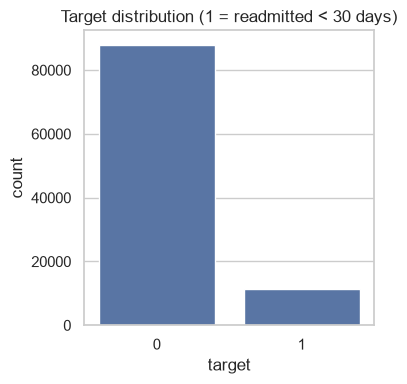

In [90]:
df["target"] = (df["readmitted"] == "<30").astype(int) #cible binaire : 1 si réadmis en moins de 30 jours sinon 0
df = df.drop(columns=["readmitted"]) #supprime la colonne d'origine pour éviter une fuite
print(df["target"].value_counts()) #nombre de positifs et de négatifs
print(df["target"].value_counts(normalize=True).round(3)) #proportions des deux classes
plt.figure(figsize=(4, 4)) #taille du graphique
sns.countplot(x="target", data=df) #barres du nombre de lignes par classe
plt.title("Target distribution (1 = readmitted < 30 days)") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche le graphique

**Ce que fait ce code :** on transforme `readmitted` (3 valeurs : `NO`, `>30`, `<30`) en cible binaire. On supprime ensuite la colonne d'origine car elle contient la réponse.

**Pourquoi ce choix :** une réadmission en moins de 30 jours est ce qui coûte cher à l'hôpital et c'est la définition classique dans la littérature. Le problème devient une classification binaire.

**Interprétation :** les classes sont très déséquilibrées avec environ 11 % de positifs. Un modèle qui prédit toujours 0 aurait environ 89 % d'accuracy sans rien apprendre. On utilisera donc le ROC-AUC et la PR-AUC dans les notebooks suivants.

## 9. Patients and repeated visits

Rows : 99340
Unique patients : 69987
count    69987.000000
mean         1.419406
std          1.086388
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
dtype: float64


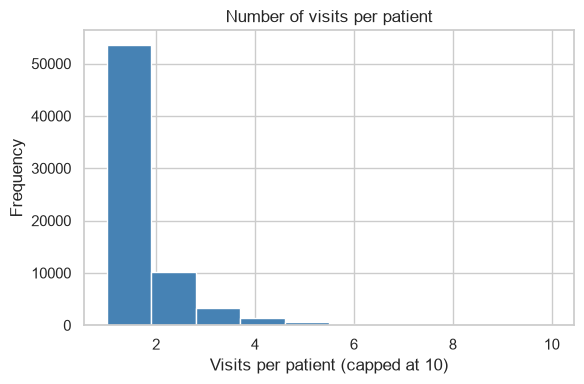

In [94]:
print("Rows :", len(df)) #nombre d'hospitalisations
print("Unique patients :", df["patient_nbr"].nunique()) #nombre de patients différents
visits = df.groupby("patient_nbr").size() #nombre d'hospitalisations par patient
print(visits.describe()) #résumé du nombre de visites par patient
plt.figure(figsize=(6, 4)) #taille du graphique
visits.clip(upper=10).plot(kind="hist", bins=10, color="steelblue") #histogramme avec les valeurs coupées à 10
plt.xlabel("Visits per patient (capped at 10)") #nom de l'axe x
plt.title("Number of visits per patient") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche le graphique
df = df.drop(columns=["encounter_id"]) #supprime l'identifiant de visite qui n'est pas une vraie variable

**Ce que fait ce code :** on compte combien de lignes il y a par patient. On supprime `encounter_id` car c'est juste un identifiant. On **garde** `patient_nbr`.

**Interprétation :** il y a moins de patients que de lignes donc un même patient apparaît plusieurs fois. Si on fait un split aléatoire un patient peut se retrouver dans le train et dans le test. C'est une fuite de données. Dans le notebook 02 on utilisera `StratifiedGroupKFold` avec `patient_nbr` comme groupe.

## 10. Exploratory analysis

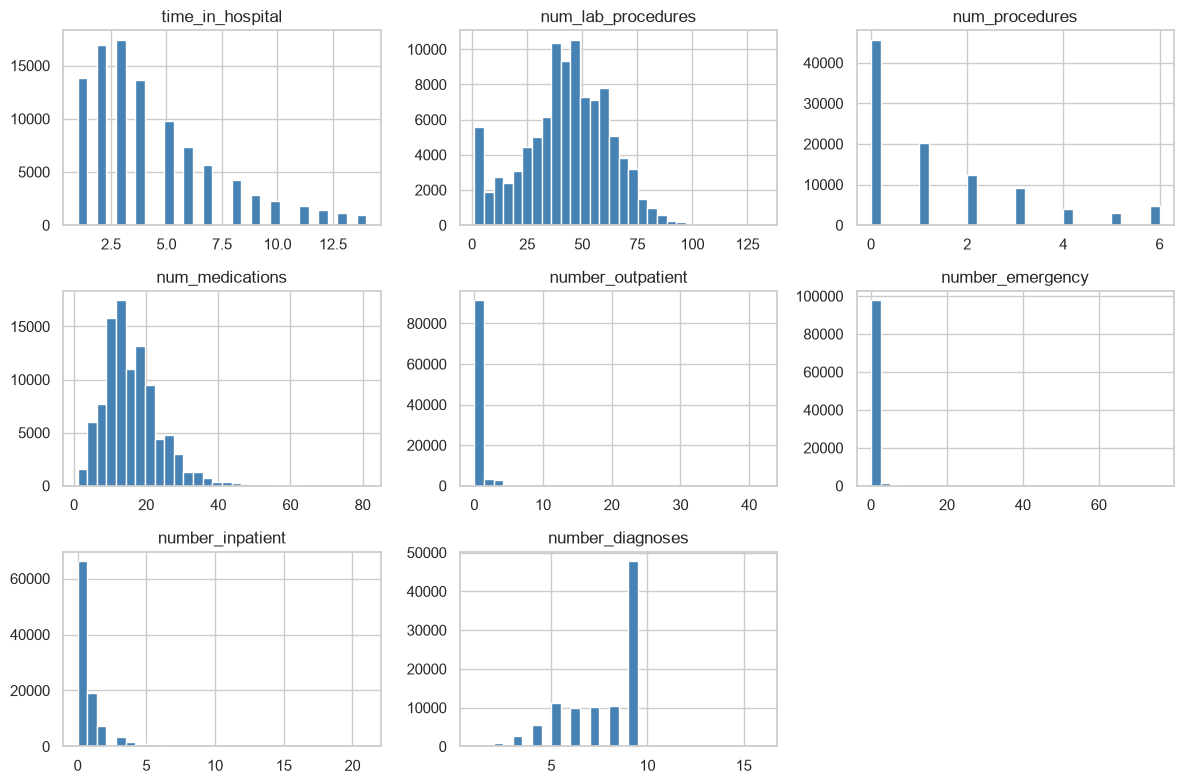

In [98]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"] #liste des variables numériques utiles
df[num_cols].hist(bins=30, figsize=(12, 8), color="steelblue") #histogramme de chaque variable numérique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche les histogrammes

**Ce que fait ce code :** un histogramme par variable numérique pour voir leur forme.

**Interprétation :** `number_outpatient`, `number_emergency` et `number_inpatient` sont très asymétriques avec beaucoup de zéros et quelques grandes valeurs. `time_in_hospital` est aussi décalée vers la gauche. Les grandes valeurs sont possibles médicalement donc on ne les supprime pas. Un modèle à base d'arbres les gère bien. Pour la régression logistique on pourra standardiser.

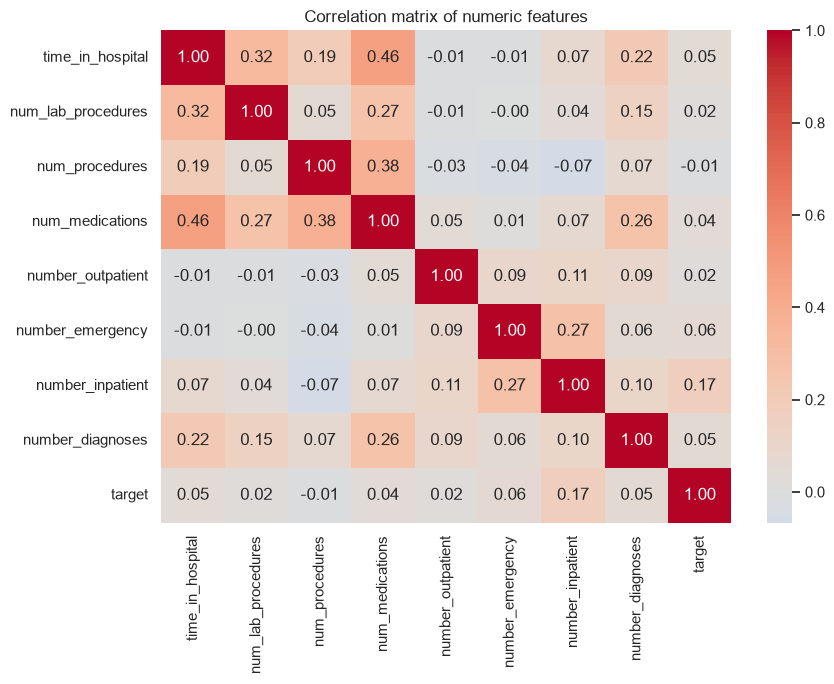

In [101]:
corr = df[num_cols + ["target"]].corr() #calcule les corrélations de Pearson
plt.figure(figsize=(9, 7)) #taille du graphique
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0) #carte de chaleur avec les valeurs
plt.title("Correlation matrix of numeric features") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche la carte de chaleur

**Ce que fait ce code :** la corrélation de Pearson mesure le lien linéaire entre deux variables (entre -1 et 1). On la calcule entre toutes les variables numériques et la cible.

**Interprétation :** les corrélations avec la cible sont faibles (souvent en dessous de 0.1). `number_inpatient` est en général la plus liée. Ça annonce un problème difficile et une AUC modeste. On voit aussi que `time_in_hospital` et `num_medications` sont un peu corrélées entre elles. Il y a donc un peu de redondance.

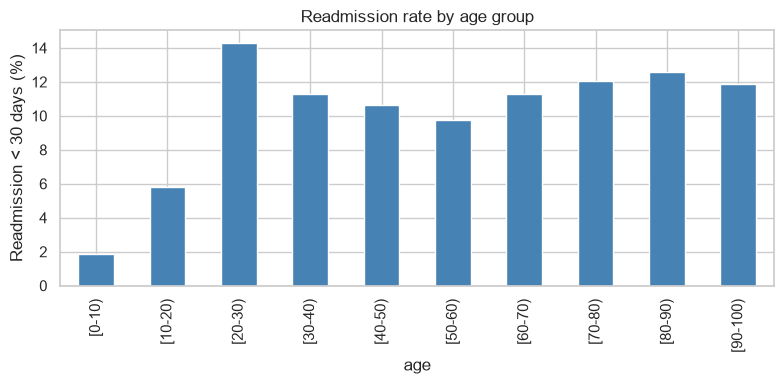

In [103]:
age_rate = df.groupby("age")["target"].mean().mul(100) #taux de réadmission en % par tranche d'âge
plt.figure(figsize=(8, 4)) #taille du graphique
age_rate.plot(kind="bar", color="steelblue") #barres du taux par tranche d'âge
plt.ylabel("Readmission < 30 days (%)") #nom de l'axe y
plt.title("Readmission rate by age group") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche le graphique

**Ce que fait ce code :** on calcule la moyenne de la cible pour chaque tranche d'âge. Comme la cible vaut 0 ou 1 cette moyenne est le taux de réadmission.

**Interprétation :** le taux change selon l'âge. Il est souvent plus faible chez les jeunes et un peu plus haut chez les patients âgés. L'écart reste modeste donc l'âge seul ne suffit pas.

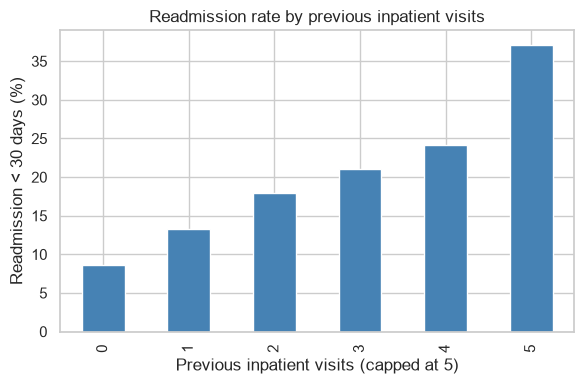

In [107]:
inp = df["number_inpatient"].clip(upper=5) #regroupe les valeurs supérieures à 5 dans la classe 5
inp_rate = df.groupby(inp)["target"].mean().mul(100) #taux de réadmission en % selon le nombre d'hospitalisations passées
plt.figure(figsize=(6, 4)) #taille du graphique
inp_rate.plot(kind="bar", color="steelblue") #barres du taux par nombre de visites passées
plt.xlabel("Previous inpatient visits (capped at 5)") #nom de l'axe x
plt.ylabel("Readmission < 30 days (%)") #nom de l'axe y
plt.title("Readmission rate by previous inpatient visits") #titre du graphique
plt.tight_layout() #évite que les textes se chevauchent
plt.show() #affiche le graphique

**Ce que fait ce code :** même calcul que pour l'âge mais avec le nombre d'hospitalisations passées. On coupe à 5 car les grandes valeurs sont rares.

**Interprétation :** le taux de réadmission monte nettement quand le nombre de visites passées augmente. C'est une des variables les plus informatives du dataset et on s'attend à la retrouver dans la sélection de variables du notebook 04.

## 11. Final check and saving

In [111]:
print("Final shape :", df.shape) #taille finale du tableau
print("Positive rate :", round(df["target"].mean(), 3)) #proportion de positifs
print("Unique patients :", df["patient_nbr"].nunique()) #vérifie que patient_nbr est bien gardé
print(df.isna().sum()[df.isna().sum() > 0]) #liste des colonnes qui ont encore des manquants
os.makedirs(PROCESSED_DIR, exist_ok=True) #crée le dossier de sortie s'il n'existe pas
df.to_csv(os.path.join(PROCESSED_DIR, "diabetes_clean.csv"), index=False) #sauvegarde le fichier nettoyé
print("Saved in", PROCESSED_DIR) #confirme la sauvegarde

Final shape : (99340, 34)
Positive rate : 0.114
Unique patients : 69987
diag_1              20
diag_2             356
diag_3            1419
max_glu_serum    94188
A1Cresult        82506
dtype: int64
Saved in ..\data\processed


**Résumé des décisions du notebook :**
- `?` remplacé par NaN. `weight` et `payer_code` supprimées.
- `medical_specialty` et `race` remplies avec une catégorie constante.
- Doublons et genres invalides retirés.
- Patients décédés ou en hospice retirés.
- Colonnes constantes ou quasi constantes supprimées.
- Cible binaire `target` (réadmission < 30 jours). La colonne `readmitted` est supprimée.
- `patient_nbr` gardé pour le split par patient. `encounter_id` supprimé.

**Attention pour le notebook 02 :** en relisant le csv les colonnes `admission_type_id`, `discharge_disposition_id` et `admission_source_id` redeviennent des nombres. Il faudra les convertir en catégories (`astype(str)`). Aucun scaling ni encodage n'est fait ici pour éviter les fuites de données. Tout sera dans un Pipeline.